# Caustics, binary labels, distances, and winding numbers

The first row constructs four registered source-plane products from one lens
realization. It includes point-source magnification, binary caustic class, distance
to the nearest caustic, and integer winding number.  The winding product needs
consistently oriented *closed* caustic contours. The package orients marching-
squares segments by the positive-$\det\mathbf{J}$ side before mapping them through the
lens equation.  Consequently its value is piecewise constant and changes only
across a plotted caustic, while its value modulo two exactly reproduces the
binary map.

The second figure reproduces the Q2237 image-B manuscript anchor/gauge panel
with the same classified probes, ray colors, scale bar, and legend placement.
The full diagnostic maps are optional. The fast light-curve calculation normally
evaluates only the source-center quantities.


In [1]:
from pathlib import Path
import numpy as np
import torch
from matplotlib import pyplot as plt
import microcaustics as mc
import microcaustics.plotting as mcp

plt.rcParams.update(mcp.publication_style())
capabilities = mc.RuntimeCapabilities.detect()
use_cuda = capabilities.cuda_available
runtime_config = mc.RuntimeConfig(
    device="cuda" if use_cuda else "cpu",
    backend="triton" if use_cuda and capabilities.triton_importable else "auto",
    dtype=torch.float32,
    strict_backend=use_cuda and capabilities.triton_importable,
)
print(mcp.runtime_description())


Python 3.11.15 | PyTorch 2.12.1+cu130 | Windows AMD64 | CUDA 13.0, NVIDIA GeForce RTX 5070 Ti, compute capability 12.0


In [2]:
stars = mc.PointMassField(
        x_uas=torch.tensor([-0.8, 0.4, 1.1]),
        y_uas=torch.tensor([0.5, -0.7, 0.2]),
        mass_solar=torch.tensor([0.003537, 0.002264, 0.001834]),
)
lens_region = mc.PlaneRegion((6.0, 6.0))
lens_resolution = 2048 if use_cuda else 768
lens_grid = mc.PlaneGrid((lens_resolution, lens_resolution), (6.0, 6.0))
# This crop is centered on a resolved caustic rather than on an empty part of
# the source plane. PlaneGrid centers use array order (y, x).
source_resolution = 1024 if use_cuda else 256
source_grid = mc.PlaneGrid(
    (source_resolution, source_resolution),
    (0.60, 0.60),
    center_uas=(-0.68, 0.35),
)
system = mc.MicrolensingSystem(
    macro=mc.MacroLens(convergence=0.25, shear=0.10),
    distances=mc.LensingDistances(8.0e24, 1.6e25, 9.0e24),
    stars=stars, source_grid=source_grid, lens_region=lens_region,
    runtime=runtime_config, caustic_grid_shape=lens_grid.shape,
)
simulation = system.realize().simulation  # full diagnostic maps use the resolved tracer
ray_count = 10_000_000 if use_cuda else 262_144


In [3]:
magnification = simulation.magnification_map(
    lens_region,
    source_grid,
    method=mc.production_ipm_config(
    scout_ratio=1,
        rays=ray_count,
        cell_chunk_size=524_288 if use_cuda else 65_536,
    ),
)
complete_field = simulation.caustics(lens_grid)
binary_map = complete_field.label_map(source_grid)
distance_map = complete_field.distance_map(source_grid)
winding_map = complete_field.winding_map(source_grid, orientation="positive")

torch.testing.assert_close(
    torch.remainder(winding_map.values, 2).to(binary_map.values.dtype),
    binary_map.values,
    rtol=0,
    atol=0,
)
print("critical/caustic segments:", complete_field.segment_count)
print("winding values:", torch.unique(winding_map.values).tolist())
print("source-center winding number:", int(winding_map.values[source_grid.shape[0] // 2, source_grid.shape[1] // 2].cpu()))


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:902: CompilationWarning: Compilation event 1: preparing a new Triton specialization for IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\direct.py:310: CompilationWarning: Compilation event 2: preparing a new torch.compile specialization for direct Jacobian block on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  (chunk_xx, chunk_xy), used = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\direct.py:195: CompilationWarning: Compilation event 3: preparing a new torch.compile specialization for direct deflection block on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  (chunk_alpha_x, chunk_alpha_y), used = run_tensor_kernel(


critical/caustic segments: 1724
winding values: [0, 1]
source-center winding number: 0


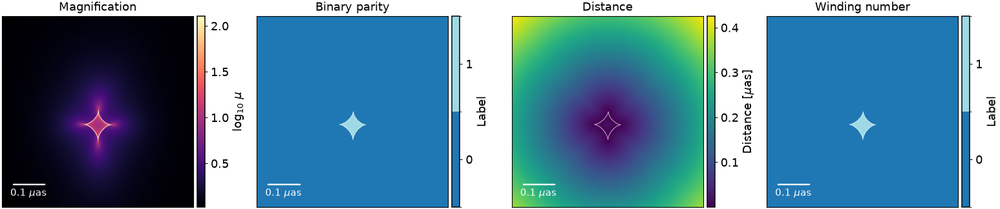

In [4]:
figure, axes = plt.subplots(1, 4, figsize=(15.8, 3.7))
mcp.plot_magnification_map(
    magnification,
    ax=axes[0],
    caustics=complete_field,
    log10=True,
    colorbar=True,
    title=r"Magnification",
    scale_bar_uas=0.1,
    show_axes=False,
)
mcp.plot_label_map(
    binary_map,
    ax=axes[1],
    caustics=complete_field,
    colorbar=True,
    title="Binary parity",
    scale_bar_uas=0.1,
    show_axes=False,
)
mcp.plot_distance_map(
    distance_map,
    ax=axes[2],
    caustics=complete_field,
    colorbar=True,
    scale_bar_uas=0.1,
    show_axes=False,
)
axes[2].set_title("Distance")
mcp.plot_label_map(
    winding_map,
    ax=axes[3],
    caustics=complete_field,
    colorbar=True,
    title="Winding number",
    scale_bar_uas=0.1,
    show_axes=False,
)
figure.tight_layout()


## Production anchor/gauge labeling at full source-map resolution

The next cell generates a Q2237 image-B magnification map, caustics, anchor/gauge labels, and optional $1024\times1024$ diagnostic maps directly with the public API. Production light curves do not construct these diagnostic maps. They evaluate only the configurable anchors, gauges, and source center. The full binary, distance, and winding fields are useful for validation and visualization.


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\lens\models.py:842: CompilationWarning: Compilation event 4: preparing a new torch.compile specialization for specular stellar-boundary evolution on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  positions, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:902: CompilationWarning: Compilation event 5: preparing a new Triton specialization for IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1291: CompilationWarning: Compilation event 6: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


Generated source-plane caustic segments: 749
Generated complete-field segments: 1170826
Binary classes: [0 1]
Distance range [microarcsec]: (1.341104507446289e-07, 2.591071605682373)
Winding classes: [0 1 2 3 4]


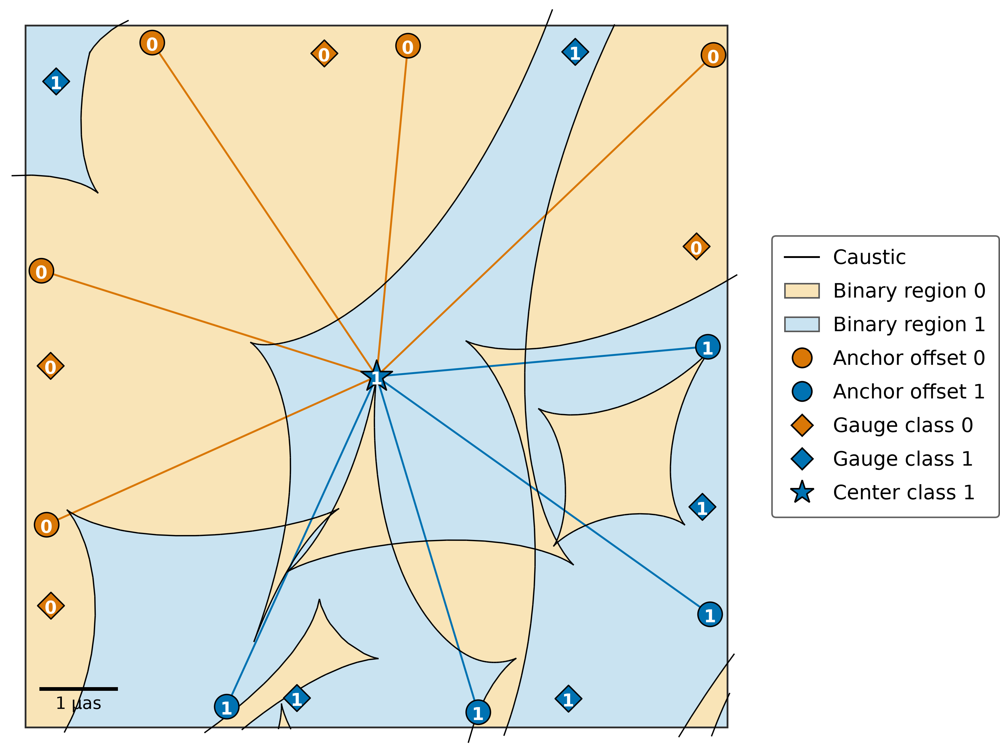

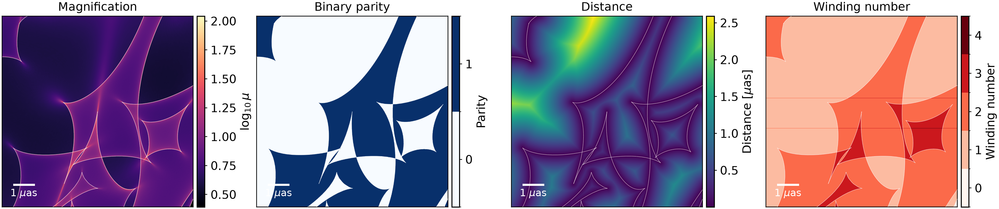

Q2237 diagnostic resolution: torch.Size([1024, 1024])


In [5]:
import sys
package_root = Path(mcp.__file__).resolve().parents[3]
examples_directory = package_root / "examples"
if str(examples_directory) not in sys.path:
    sys.path.insert(0, str(examples_directory))
from training_set_support import q2237_b_system

q_resolution = 1024 if use_cuda else 256
q_label_resolution = 8192 if use_cuda else 1024
q_training = q2237_b_system(
    seed=0, driver_seed=0, device="cuda" if use_cuda else "cpu",
    times_days=torch.tensor([0.0, 3650.0]),
    source_resolution=q_resolution, label_resolution=q_label_resolution,
)
q_realization = q_training.realization
q_simulation = q_realization.simulation
q_method = mc.production_ipm_config(
    rays=10_000_000 if use_cuda else 262_144,
)
q_caustic_config = mc.CausticConfig(
    far_field_approx=q_method.far_field_approx,
    anchor_count=9, gauge_count=9,
    temporal_batch_size=40, jacobian_chunk_size=1_048_576,
)
# The absolute source-plane origin is arbitrary for this static diagnostic.
# Generate the complete field first and center the displayed aperture on the
# caustic nearest the nominal origin, so the label construction is visible.
complete_field = q_simulation.caustics(
    q_realization.lens_grid, far_field_approx=q_method.far_field_approx,
)
complete_segments = complete_field.caustic_segments_uas
complete_valid = torch.all(torch.isfinite(complete_segments), dim=(1, 2))
complete_midpoints = complete_segments[complete_valid].mean(dim=1)
nearest_caustic = complete_midpoints[
    torch.argmin(torch.sum(complete_midpoints.square(), dim=1))
]
source_fov = q_realization.source_grid.field_of_view_uas
q_grid = mc.PlaneGrid(
    (q_resolution, q_resolution), source_fov,
    center_uas=(float(nearest_caustic[1]), float(nearest_caustic[0])),
)
q_generated = next(iter(q_simulation.dynamic_labeled_maps(
    q_realization.lens_region, q_grid, q_realization.lens_grid, [0.0],
    method=q_method, map_schedule=mc.production_dynamic_config(),
    caustic_config=q_caustic_config, diagnostic_grid=q_grid,
    include_distance_map=True,
)))
q_magnification_map = q_generated.magnification_map
frame = q_generated.caustics
q_field = frame.caustics
registered_binary = frame.label_map
q_distance = frame.distance_map
segments = q_field.caustic_segments_uas
source_extent = np.asarray(q_grid.bounds_uas, dtype=float)
q_magnification = q_magnification_map.values.detach().cpu().numpy()
winding_values = complete_field.winding_map(
    q_grid, orientation="positive",
).values.detach().cpu().numpy()
print("Generated source-plane caustic segments:", q_field.segment_count)
print("Generated complete-field segments:", complete_field.segment_count)
print("Binary classes:", np.unique(registered_binary.values.detach().cpu().numpy()))
print("Distance range [microarcsec]:", (
    float(q_distance.values_uas.min()), float(q_distance.values_uas.max()),
))
print("Winding classes:", np.unique(winding_values))

anchor_output = Path("caustic_label_output")
anchor_output.mkdir(parents=True, exist_ok=True)
from IPython.display import Image, display

# Both figures below are rendered directly from the public products calculated
# above. No archived manuscript arrays are opened by this notebook.
anchor_path = mcp.render_live_paper_anchor_gauge(frame, anchor_output)
display(Image(filename=str(anchor_path)))

winding_map = complete_field.winding_map(q_grid, orientation="positive")
diagnostic_figure, diagnostic_axes = mcp.plot_caustic_diagnostics(
    q_magnification_map,
    registered_binary,
    q_distance,
    winding_map,
    caustics=q_field,
    scale_bar_uas=1.0,
)
diagnostic_path = anchor_output / "q2237b_magnification_binary_distance_winding.png"
diagnostic_figure.savefig(
    diagnostic_path, dpi=220, bbox_inches="tight", facecolor="white"
)
plt.close(diagnostic_figure)
display(Image(filename=str(diagnostic_path)))
print("Q2237 diagnostic resolution:", registered_binary.values.shape)


## Dynamic magnification, binary, and distance maps

This final example streams a full ten-year Q2237 image-B-like production
sequence. The expensive magnification maps are evaluated on the usual
$1024^2$ source grid. Binary caustic class and nearest-caustic distance are optional
display products evaluated on a registered $256^2$ diagnostic grid. That
display grid does not alter the map, caustic extraction, source-center labels,
or any finite-source photometry. Winding maps are intentionally omitted from
the animation because reconstructing every closed contour at every epoch is a
substantially more expensive diagnostic.

All three panels use one normalization for the complete animation. The binary
colorbar remains integer-valued, and the same-epoch caustics are overlaid in
the source-plane coordinate convention. The GIF writer also quantizes every
frame against one shared palette, so a fixed colorbar cannot flicker because
of frame-by-frame palette changes.

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1291: CompilationWarning: Compilation event 7: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


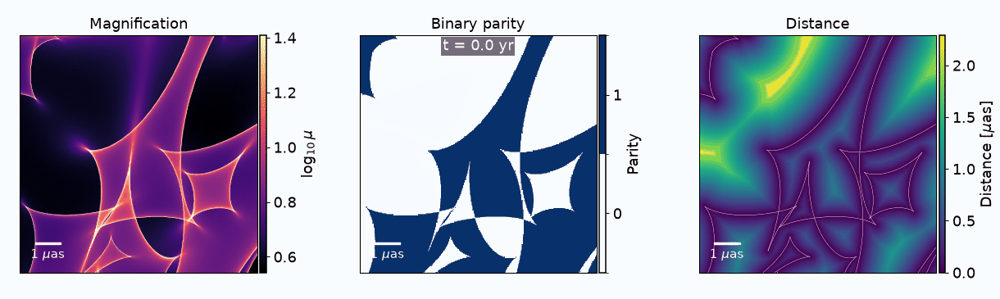

Wrote caustic_label_output\q2237b_magnification_binary_distance.gif
Frames: 147 diagnostic resolution: (256, 256)


In [6]:
import sys
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm
from IPython.display import Image, display

package_root = Path(mcp.__file__).resolve().parents[3]
examples_directory = package_root / "examples"
if str(examples_directory) not in sys.path:
    sys.path.insert(0, str(examples_directory))
from training_set_support import q2237_b_system

animation_times = torch.arange(0.0, 3650.0 + 12.5, 25.0)
training_system = q2237_b_system(
    seed=0,
    driver_seed=0,
    device="cuda" if use_cuda else "cpu",
    times_days=torch.arange(-200.0, 3651.0),
    source_resolution=1024 if use_cuda else 256,
    label_resolution=8192 if use_cuda else 1024,
)
diagnostic_resolution = 256 if use_cuda else 128
diagnostic_grid = mc.PlaneGrid(
    (diagnostic_resolution, diagnostic_resolution),
    training_system.source_grid.field_of_view_uas,
    center_uas=training_system.source_grid.center_uas,
)
animation_method = mc.production_ipm_config(
        rays=10_000_000 if use_cuda else 262_144,
)
animation_schedule = mc.production_dynamic_config()
animation_caustics = mc.CausticConfig(far_field_approx=animation_method.far_field_approx)

log_magnification_frames = []
binary_frames = []
distance_frames = []
caustic_segments = []
pool_factor = training_system.source_grid.shape[0] // diagnostic_resolution
for frame in training_system.simulation.dynamic_labeled_maps(
    training_system.lens_region,
    training_system.source_grid,
    training_system.lens_grid,
    animation_times.tolist(),
    method=animation_method,
    map_schedule=animation_schedule,
    caustic_config=animation_caustics,
    diagnostic_grid=diagnostic_grid,
    include_distance_map=True,
):
    values = frame.magnification_map.values
    if pool_factor > 1:
        values = torch.nn.functional.avg_pool2d(
            values[None, None], kernel_size=pool_factor, stride=pool_factor
        )[0, 0]
    log_magnification_frames.append(
        torch.log10(values.clamp_min(1.0e-12)).detach().cpu().numpy()
    )
    binary_frames.append(frame.caustics.label_map.values.detach().cpu().numpy())
    distance_frames.append(frame.caustics.distance_map.values_uas.detach().cpu().numpy())
    field = frame.caustics.caustics
    valid = field.invalid_segment_mask
    if valid is None:
        valid = torch.ones(field.segment_count, device=field.caustic_segments_uas.device, dtype=torch.bool)
    else:
        valid = ~valid
    caustic_segments.append(field.caustic_segments_uas[valid].detach().cpu().numpy())

log_magnification_frames = np.stack(log_magnification_frames)
binary_frames = np.stack(binary_frames)
distance_frames = np.stack(distance_frames)
mag_vmin, mag_vmax = np.nanquantile(log_magnification_frames, (0.002, 0.998))
distance_vmax = float(np.nanquantile(distance_frames, 0.998))

figure, axes = plt.subplots(1, 3, figsize=(12.2, 3.65))
common = dict(origin="lower", extent=diagnostic_grid.bounds_uas, aspect="equal")
artists = [
    axes[0].imshow(log_magnification_frames[0], cmap="magma", vmin=mag_vmin, vmax=mag_vmax, **common),
    axes[1].imshow(
        binary_frames[0], cmap=plt.colormaps["Blues"].resampled(2),
        norm=BoundaryNorm((-0.5, 0.5, 1.5), 2), interpolation="nearest", **common,
    ),
    axes[2].imshow(distance_frames[0], cmap="viridis", vmin=0.0, vmax=distance_vmax, **common),
]
titles = ("Magnification", "Binary parity", "Distance")
line_collections = []
for axis, title in zip(axes, titles, strict=True):
    axis.set_title(title)
    lines = LineCollection(caustic_segments[0], colors="white", linewidths=0.35, alpha=0.85)
    axis.add_collection(lines, autolim=False)
    line_collections.append(lines)
    axis.set_xlim(diagnostic_grid.bounds_uas[0], diagnostic_grid.bounds_uas[1])
    axis.set_ylim(diagnostic_grid.bounds_uas[2], diagnostic_grid.bounds_uas[3])
    mcp.add_scale_bar(axis, 1.0, label=r"1 $\mu$as", color="white")
    mcp.hide_image_axes(axis)
mcp.panel_colorbar(figure, axes[0], artists[0], label=r"$\log_{10}\mu$", size="2.5%", pad=0.035)
mcp.panel_colorbar(figure, axes[1], artists[1], label="Parity", ticks=(0, 1), size="2.5%", pad=0.035)
mcp.panel_colorbar(figure, axes[2], artists[2], label=r"Distance [$\mu$as]", size="2.5%", pad=0.035)
time_text = axes[1].text(
    0.50, 0.985, "", transform=axes[1].transAxes, ha="center", va="top",
    color="white", bbox={"facecolor": "black", "edgecolor": "none", "alpha": 0.55, "pad": 1.5},
)
# Reserve canvas space for the final colorbar and its labels.
figure.subplots_adjust(left=0.02, right=0.945, bottom=0.06, top=0.91, wspace=0.38)

rendered_frames = []
for frame_index, time_day in enumerate(animation_times):
    artists[0].set_data(log_magnification_frames[frame_index])
    artists[1].set_data(binary_frames[frame_index])
    artists[2].set_data(distance_frames[frame_index])
    for lines in line_collections:
        lines.set_segments(caustic_segments[frame_index])
    time_text.set_text(f"t = {float(time_day) / 365.0:.1f} yr")
    figure.canvas.draw()
    rendered_frames.append(np.asarray(figure.canvas.buffer_rgba())[..., :3].copy())

animation_directory = Path("caustic_label_output")
animation_directory.mkdir(exist_ok=True)
animation_path = animation_directory / "q2237b_magnification_binary_distance.gif"
mcp.save_fixed_palette_gif(rendered_frames, animation_path, fps=8, dither=True)
plt.close(figure)
display(Image(filename=str(animation_path)))
print("Wrote", animation_path)
print("Frames:", len(rendered_frames), "diagnostic resolution:", diagnostic_grid.shape)
